In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anasmohammedtahir/covidqu")

print("Path to dataset files:", path)

100%|██████████| 1.15G/1.15G [00:57<00:00, 21.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/anasmohammedtahir/covidqu/versions/7


In [3]:
import os
import glob

# Explore the directory structure of the downloaded dataset
print("Dataset directory contents:")
for root, dirs, files in os.walk(path):
    # Only print top levels to keep it clean
    level = root.replace(path, '').count(os.sep)
    if level < 3:
        indent = ' ' * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

Dataset directory contents:
7/
    Lung Segmentation Data/
        Lung Segmentation Data/
    Infection Segmentation Data/
        Infection Segmentation Data/


In [4]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Define the base data directory for Lung Segmentation Data (which contains images for COVID, Non-COVID, Normal)
base_dir = os.path.join(path, "Lung Segmentation Data", "Lung Segmentation Data")
print("Base directory:", base_dir)

# Let's inspect the sets inside this directory
sets = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
print("Sets found:", sets)

# Build a DataFrame of all images across Train, Val, and Test to inspect our classes
data_list = []
for dataset_type in ['Train', 'Val', 'Test']:
    dataset_path = os.path.join(base_dir, dataset_type)
    if not os.path.exists(dataset_path):
        continue
    for category in os.listdir(dataset_path):
        category_path = os.path.join(dataset_path, category)
        if os.path.isdir(category_path):
            # Looking for images in category_path/images or directly in category_path
            img_dir = os.path.join(category_path, 'images')
            if os.path.exists(img_dir):
                target_dir = img_dir
            else:
                target_dir = category_path

            images = glob.glob(os.path.join(target_dir, '*.png')) + glob.glob(os.path.join(target_dir, '*.jpg'))
            for img in images:
                data_list.append({
                    'filepath': img,
                    'class': category,
                    'split': dataset_type
                })

df = pd.DataFrame(data_list)
print(f"Total images found: {len(df)}")
print(df.groupby(['split', 'class']).size().reset_index(name='count'))

Base directory: /root/.cache/kagglehub/datasets/anasmohammedtahir/covidqu/versions/7/Lung Segmentation Data/Lung Segmentation Data
Sets found: ['Val', 'Test', 'Train']
Total images found: 33920
   split      class  count
0   Test   COVID-19   2395
1   Test  Non-COVID   2253
2   Test     Normal   2140
3  Train   COVID-19   7658
4  Train  Non-COVID   7208
5  Train     Normal   6849
6    Val   COVID-19   1903
7    Val  Non-COVID   1802
8    Val     Normal   1712


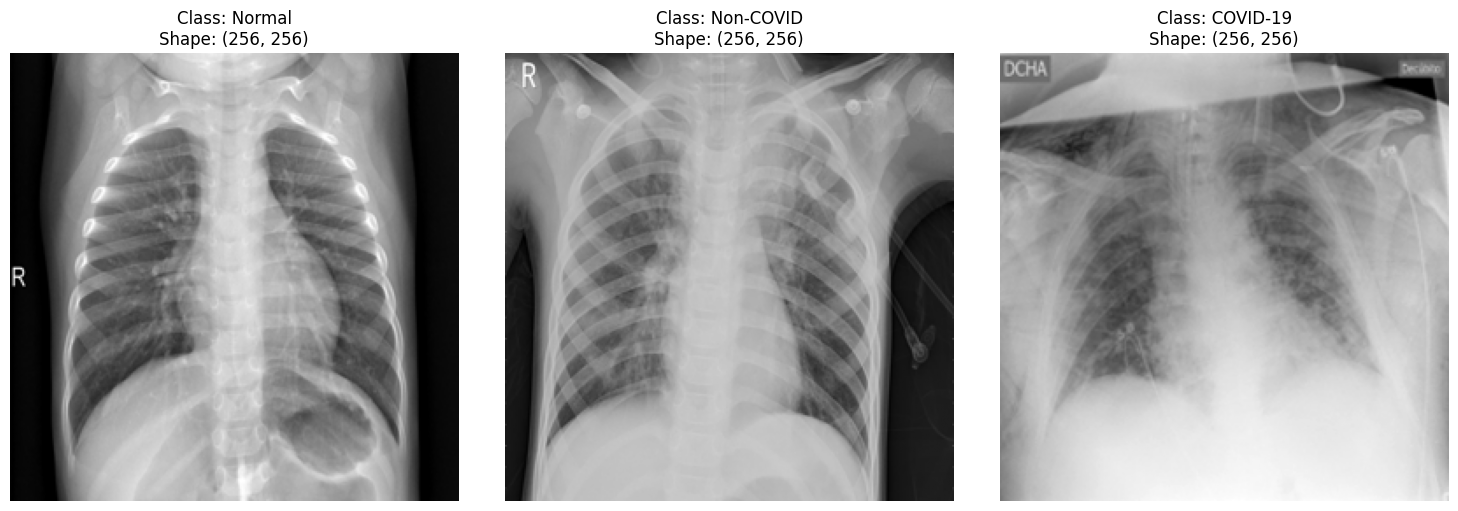

In [5]:
# Display example images from each class
unique_classes = df['class'].unique()
plt.figure(figsize=(15, 5))
for i, cls in enumerate(unique_classes):
    sample = df[df['class'] == cls].iloc[0]
    img = Image.open(sample['filepath'])
    plt.subplot(1, len(unique_classes), i + 1)
    plt.imshow(img, cmap='gray' if img.mode == 'L' else None)
    plt.title(f"Class: {cls}\nShape: {img.size}")
    plt.axis('off')
plt.tight_layout()
plt.show()

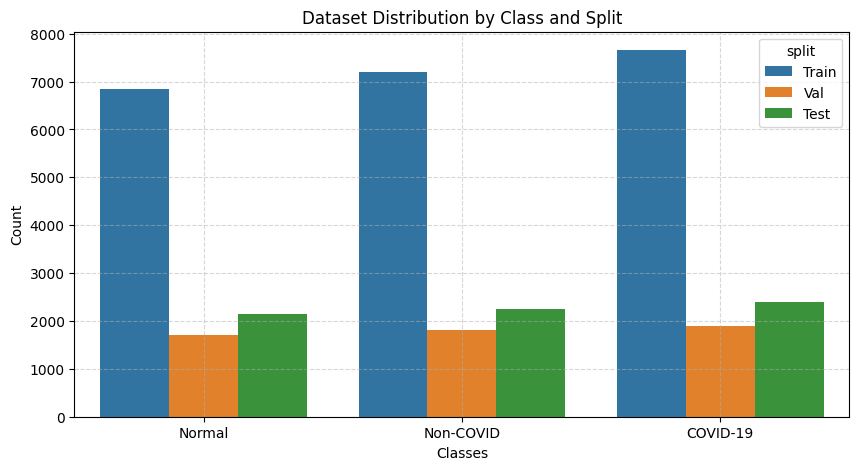

In [6]:
# Display all graphs/distributions
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='class', hue='split')
plt.title('Dataset Distribution by Class and Split')
plt.xlabel('Classes')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

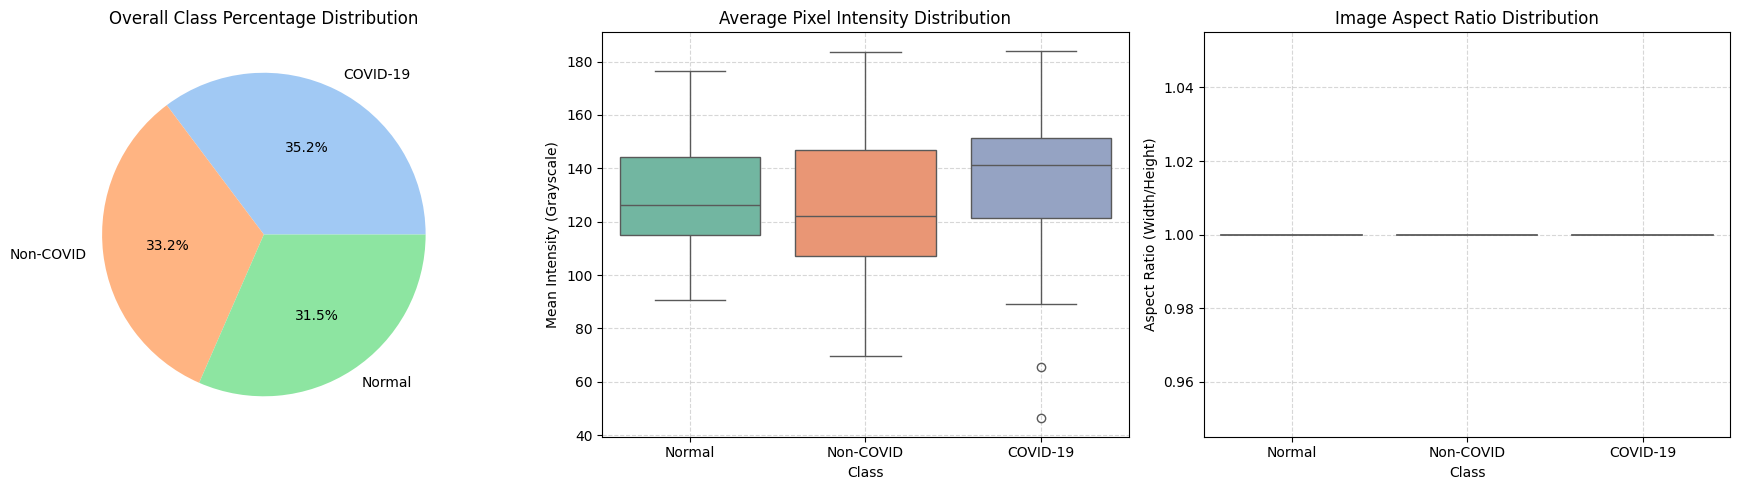

In [17]:
import numpy as np
import cv2

# Let's collect image sizes and average pixel intensities for a small sample from each class to visualize
sample_data = []
for cls in unique_classes:
    samples = df[df['class'] == cls].sample(n=100, random_state=42)
    for _, row in samples.iterrows():
        img_path = row['filepath']
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            height, width = img.shape
            mean_val = np.mean(img)
            sample_data.append({
                'class': cls,
                'width': width,
                'height': height,
                'mean_intensity': mean_val,
                'aspect_ratio': width / height
            })

sample_df = pd.DataFrame(sample_data)

# Create extra diagnostic graphs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graph 1: Percentage Distribution of Classes overall
class_counts = df['class'].value_counts()
axes[0].pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
axes[0].set_title('Overall Class Percentage Distribution')

# Graph 2: Distribution of Average Pixel Intensities by Class
sns.boxplot(data=sample_df, x='class', y='mean_intensity', ax=axes[1], palette='Set2', hue='class', legend=False)
axes[1].set_title('Average Pixel Intensity Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Mean Intensity (Grayscale)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Graph 3: Aspect Ratio Distribution by Class
sns.violinplot(data=sample_df, x='class', y='aspect_ratio', ax=axes[2], palette='muted', hue='class', legend=False)
axes[2].set_title('Image Aspect Ratio Distribution')
axes[2].set_xlabel('Class')
axes[2].set_ylabel('Aspect Ratio (Width/Height)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configure image size and batch size
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Set up direct directories for Train, Val, and Test pipelines
train_dir = os.path.join(base_dir, 'Train')
val_dir = os.path.join(base_dir, 'Val')
test_dir = os.path.join(base_dir, 'Test')

# Generators without heavy augmentations (no optimization requested)
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 43430 images belonging to 3 classes.
Found 10834 images belonging to 3 classes.
Found 13576 images belonging to 3 classes.


In [8]:
# Model 1: Simple Custom CNN
model_1 = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(train_generator.class_indices), activation='softmax')
])

model_1.compile(optimizer='adam', loss='categorical_balance' if False else 'categorical_crossentropy', metrics=['accuracy'])
model_1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,707 (28.20 MB)

 Trainable params: 7,392,707 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Model 2: Lightweight pre-trained MobileNetV2 base (no fine-tuning/optimization)
base_model = tf.keras.applications.MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Keep frozen

model_2 = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(len(train_generator.class_indices), activation='softmax')
])

model_2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
# Train Model 1 (Short epochs for performance without optimization)
print("--- Training Model 1: Custom CNN ---")
history_1 = model_1.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

--- Training Model 1: Custom CNN ---
Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 102s 75ms/step - accuracy: 0.8860 - loss: 0.2870 - val_accuracy: 0.7226 - val_loss: 0.7962
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 101s 74ms/step - accuracy: 0.9423 - loss: 0.1518 - val_accuracy: 0.7281 - val_loss: 1.0313
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 107s 79ms/step - accuracy: 0.9693 - loss: 0.0854 - val_accuracy: 0.7244 - val_loss: 1.3254
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 109s 80ms/step - accuracy: 0.9795 - loss: 0.0587 - val_accuracy: 0.7207 - val_loss: 1.5443
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 105s 78ms/step - accuracy: 0.9854 - loss: 0.0440 - val_accuracy: 0.7197 - val_loss: 1.7597


In [14]:
# Train Model 2: Transfer Learning MobileNetV2
print("--- Training Model 2: Transfer Learning MobileNetV2 ---")
history_2 = model_2.fit(
    train_generator,
    validation_data=val_generator,
    epochs=4
)

--- Training Model 2: Transfer Learning MobileNetV2 ---
Epoch 1/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 98s 72ms/step - accuracy: 0.7578 - loss: 0.5607 - val_accuracy: 0.7608 - val_loss: 0.5589
Epoch 2/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 100s 73ms/step - accuracy: 0.7692 - loss: 0.5349 - val_accuracy: 0.7642 - val_loss: 0.5451
Epoch 3/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 104s 77ms/step - accuracy: 0.7804 - loss: 0.5131 - val_accuracy: 0.7645 - val_loss: 0.5545
Epoch 4/4
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 106s 78ms/step - accuracy: 0.7868 - loss: 0.4955 - val_accuracy: 0.7668 - val_loss: 0.5491


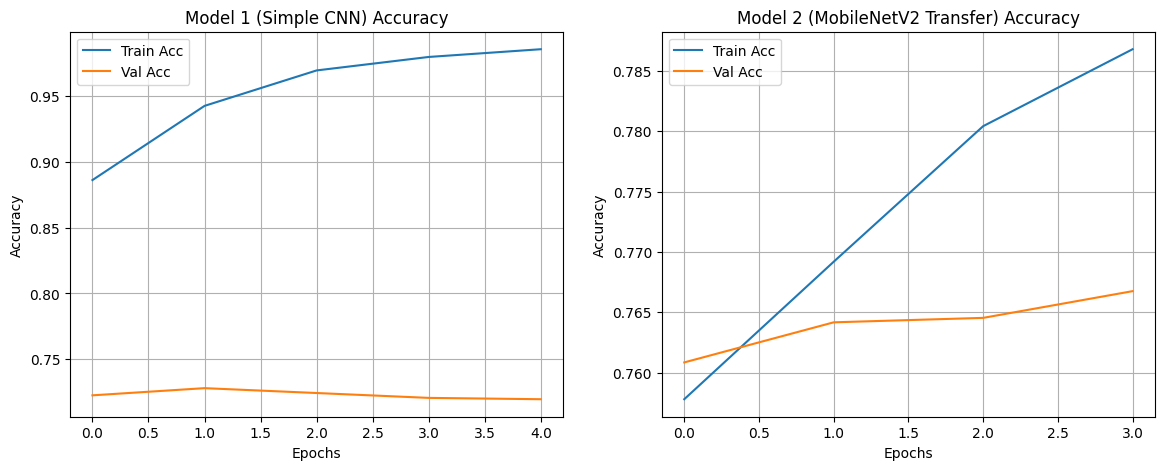

In [15]:
# Plot Training and Validation curves for both models
plt.figure(figsize=(14, 5))

# Model 1 Curves
plt.subplot(1, 2, 1)
plt.plot(history_1.history['accuracy'], label='Train Acc')
plt.plot(history_1.history['val_accuracy'], label='Val Acc')
plt.title('Model 1 (Simple CNN) Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Model 2 Curves
plt.subplot(1, 2, 2)
plt.plot(history_2.history['accuracy'], label='Train Acc')
plt.plot(history_2.history['val_accuracy'], label='Val Acc')
plt.title('Model 2 (MobileNetV2 Transfer) Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()


=============== Evaluating Model 1: Custom CNN ===============
425/425 ━━━━━━━━━━━━━━━━━━━━ 34s 79ms/step
Classification Report:
              precision    recall  f1-score   support

    COVID-19       0.76      0.75      0.75      4790
   Non-COVID       0.72      0.73      0.72      4506
      Normal       0.74      0.74      0.74      4280

    accuracy                           0.74     13576
   macro avg       0.74      0.74      0.74     13576
weighted avg       0.74      0.74      0.74     13576



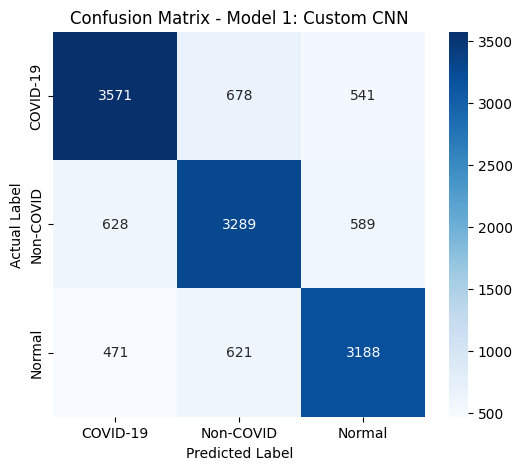


=============== Evaluating Model 2: MobileNetV2 ===============
425/425 ━━━━━━━━━━━━━━━━━━━━ 33s 68ms/step
Classification Report:
              precision    recall  f1-score   support

    COVID-19       0.75      0.82      0.79      4790
   Non-COVID       0.85      0.71      0.78      4506
      Normal       0.78      0.83      0.80      4280

    accuracy                           0.79     13576
   macro avg       0.79      0.79      0.79     13576
weighted avg       0.79      0.79      0.79     13576



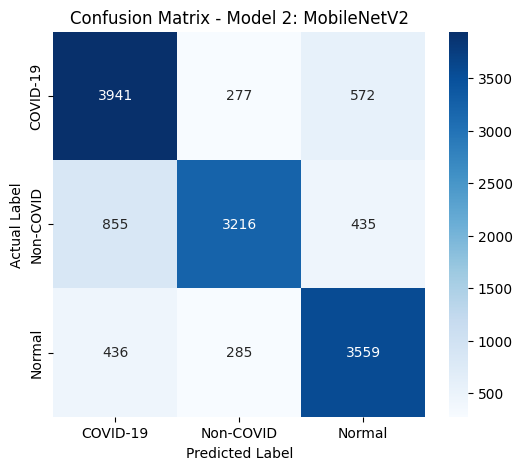

In [16]:
# Evaluate metrics including Accuracy, Confusion Matrix and Classification Report
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, name):
    print(f"\n{'='*15} Evaluating {name} {'='*15}")
    # Reset test generator to start from the beginning
    test_generator.reset()
    predictions = model.predict(test_generator)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = test_generator.classes
    class_labels = list(test_generator.class_indices.keys())

    # Display classification report
    print("Classification Report:")
    print(classification_report(true_classes, predicted_classes, target_names=class_labels))

    # Plot Confusion Matrix
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

evaluate_model(model_1, "Model 1: Custom CNN")
evaluate_model(model_2, "Model 2: MobileNetV2")